In [4]:
# imports
from covderivatives import torchdiff1D, sqexptorch 
import matplotlib.pyplot as plt
import torch
import numpy as np

In [ ]:
# constraint Y(x) = Y''(x)  
theta = 2                                 # theta = 0.5, 2 
x = torch.tensor(1.0, dtype = float)
k = sqexptorch(x, x,theta)
h = torchdiff1D(x, x, sqexptorch, 2, 0, thetaval = theta)
d = torchdiff1D(x, x, sqexptorch, 2, 2, thetaval = theta)

# Simple Kriging objective 
# def Obj(a1, a2):
#     return k*a1**2  - 2*a1*k

def Obj(a1, a2):
    return k*a1**2  - 2*a1*k + k + k*a2**2 - 2*a2*h + d 

dom = np.linspace(0, 1, 100)
Objective = np.zeros((100, 100))
for _i in range(100):
    for _j in range(100):
        Objective[_i, _j] = Obj(dom[_i], dom[_j])

[Text(1, 0.175, 'low'), Text(1, 2.7, 'high')]

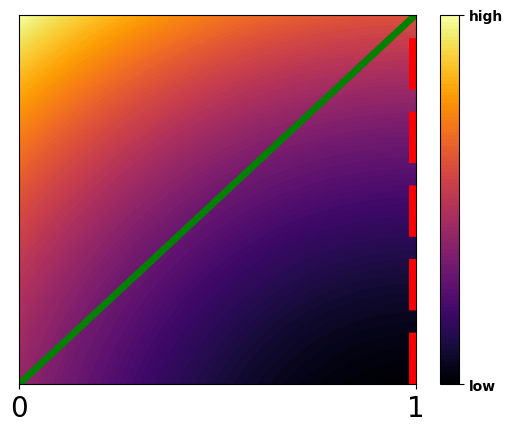

In [200]:
dom_x, dom_y = np.meshgrid(dom, dom)
cm = plt.contourf(dom_x, dom_y, Objective.T, levels = 100, cmap= 'inferno')
plt.plot(dom, dom, c = 'green', lw = 5)
plt.plot(100*[1.0], dom, c = 'red', linestyle = 'dashed', lw = 10)
plt.xticks([0.0, 1.0], fontsize = 20)
# plt.xlabel(r'\alpha')
plt.yticks([])
cbar = plt.colorbar(cm, ticks=[0.175, 2.70])
cbar.ax.set_yticklabels(['low', 'high'], weight = 'bold')  # vertically oriented colorbar
# plt.plot(dom, 100*[0.1], c = 'red', linestyle = '<->', lw = 10)
# plt.colorbar()